In [2]:
# ============================================================
# 1. IMPORT LIBRARIES AND LOAD DATA
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent style for all charts
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# Load the dataset exported from MySQL
# This is our SQL → Python handoff file.
df = pd.read_csv("../sql/query_result.csv")

print("Original Dataset Shape:", df.shape)

# Display the first 5 rows to understand the structure
df.head()

Original Dataset Shape: (101525, 28)


,collision_index,collision_year,collision_severity,date,day_of_week,time,longitude,latitude,road_type,speed_limit,...,urban_or_rural_area,trunk_road_flag,number_of_vehicles,number_of_casualties,vehicle_count,avg_driver_age,casualty_count,fatal_casualties,serious_casualties,slight_casualties
0,2025010588931,2025,3,26/07/2025,7,23:17,-0.19989,51.58970,3,40,...,1,2,3,3,3,54.7,3,0,0,3
1,2025131686006,2025,3,19/12/2025,6,10:20,-1.77859,53.65991,6,30,...,1,2,2,3,2,50.0,3,0,0,3
2,2025010558907,2025,2,12/02/2025,4,16:45,0.06845,51.52371,3,50,...,2,2,3,1,3,44.0,1,0,1,0
3,2025430550042,2025,3,25/10/2025,7,10:10,-0.81472,51.82750,6,30,...,1,2,2,2,2,30.0,2,0,0,2
4,2025461646829,2025,3,20/09/2025,7,22:00,0.22032,51.28865,6,30,...,1,2,2,1,2,46.0,1,0,0,1


In [ ]:
# ============================================================
# 2. INITIAL DATA UNDERSTANDING
# ============================================================

# Show the number of rows, columns, data types and non-null values
df.info()

# Show basic statistics for numerical columns
display(df.describe())

# Check for missing values in each column
missing = df.isnull().sum()
#.mean() gives us the proportion of missing values.
missing_pct = (df.isnull().mean() * 100).round(2)

missing_summary = pd.DataFrame({
    "missing_count": missing,
    "missing_pct": missing_pct
})

print("Missing Values:")
display(missing_summary[missing_summary["missing_count"] > 0])

# Check for exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 101525 entries, 0 to 101524
Data columns (total 28 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   collision_index             101525 non-null  str    
 1   collision_year              101525 non-null  int64  
 2   collision_severity          101525 non-null  int64  
 3   date                        101525 non-null  str    
 4   day_of_week                 101525 non-null  int64  
 5   time                        101525 non-null  str    
 6   longitude                   101523 non-null  float64
 7   latitude                    101523 non-null  float64
 8   road_type                   101525 non-null  int64  
 9   speed_limit                 101525 non-null  int64  
 10  first_road_class            101525 non-null  int64  
 11  junction_detail             101525 non-null  int64  
 12  junction_control            101525 non-null  int64  
 13  light_conditions         

,collision_year,collision_severity,day_of_week,longitude,latitude,road_type,speed_limit,first_road_class,junction_detail,junction_control,...,urban_or_rural_area,trunk_road_flag,number_of_vehicles,number_of_casualties,vehicle_count,avg_driver_age,casualty_count,fatal_casualties,serious_casualties,slight_casualties
count,101525.0,101525.000000,101525.000000,101523.000000,101523.000000,101525.000000,101525.000000,101525.000000,101525.000000,101525.000000,...,101525.000000,101525.000000,101525.000000,101525.000000,101525.000000,95497.000000,101525.000000,101525.000000,101525.000000,101525.000000
mean,2025.0,2.723250,4.126097,-1.223959,52.375658,5.212815,35.771189,4.245762,8.323861,1.756641,...,1.338646,1.726461,1.811849,1.259621,1.811849,41.453884,1.259621,0.015149,0.273410,0.971061
std,0.0,0.478315,1.926299,1.356983,1.308239,1.707555,14.638300,1.466336,13.209492,2.692095,...,0.473335,0.786635,0.689631,0.816679,0.689631,14.947626,0.816679,0.129960,0.513026,0.839529
min,2025.0,1.000000,1.000000,-7.417720,49.912530,1.000000,20.000000,-1.000000,-1.000000,-1.000000,...,1.000000,-1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,2025.0,2.000000,2.000000,-2.118700,51.464460,6.000000,30.000000,3.000000,0.000000,-1.000000,...,1.000000,2.000000,1.000000,1.000000,1.000000,30.000000,1.000000,0.000000,0.000000,1.000000
50%,2025.0,3.000000,4.000000,-1.138910,51.888640,6.000000,30.000000,4.000000,0.000000,2.000000,...,1.000000,2.000000,2.000000,1.000000,2.000000,40.000000,1.000000,0.000000,0.000000,1.000000
75%,2025.0,3.000000,6.000000,-0.137910,53.325860,6.000000,40.000000,6.000000,13.000000,4.000000,...,2.000000,2.000000,2.000000,1.000000,2.000000,51.000000,1.000000,0.000000,1.000000,1.000000
max,2025.0,3.000000,7.000000,1.755590,60.345250,9.000000,70.000000,6.000000,99.000000,9.000000,...,3.000000,2.000000,17.000000,142.000000,17.000000,97.000000,142.000000,4.000000,27.000000,115.000000


Missing Values:


,missing_count,missing_pct
longitude,2,0.00
latitude,2,0.00
avg_driver_age,6028,5.94


Exact duplicate rows: 0


In [ ]:
# ============================================================
# 3. DATA CLEANING
# ============================================================

# Remove exact duplicate rows if any exist.
# We do this because duplicate collision records could affect
# our counts and analysis.
before_duplicates = len(df)

df = df.drop_duplicates().reset_index(drop=True)

print("Duplicate rows removed:", before_duplicates - len(df))

# IMPORTANT:
# We do NOT remove rows with missing latitude/longitude.
# A collision can still be a valid collision even if its
# coordinates are unavailable.
# Those records will simply be unavailable for mapping.
#By mapping, I mean putting the collision locations on a map using their latitude and longitude.
#If a collision has no latitude/longitude, we can't place that particular collision on the map,
# but we can still use all its other information (severity, weather, speed limit, time, etc.).

print("Missing latitude:", df["latitude"].isna().sum())
print("Missing longitude:", df["longitude"].isna().sum())

# IMPORTANT:
# We do NOT replace missing average driver ages with invented values.
# Missing driver age will remain NaN and will simply be ignored
# when calculating age-based statistics.
#since Pandas excludes the missing values from calculations like mean(), rather than treating them as 0 or inventing an age.
#And if we group by age: df.groupby("driver_age_group")
# the rows where driver_age_group is NaN are also not included in the groups by default.

print("Missing average driver age:", df["avg_driver_age"].isna().sum())

Duplicate rows removed: 0
Missing latitude: 2
Missing longitude: 2
Missing average driver age: 6028


In [ ]:

# ============================================================
# 4. CREATE DATE AND TIME FEATURES
# ============================================================

# Convert the date column from text into a proper datetime format.
# errors="coerce" converts invalid dates into NaN instead of
# creating incorrect values.
df["date"] = pd.to_datetime(
    df["date"],
    format="%d/%m/%Y",
    errors="coerce"
)

# Extract useful time-based features from the date
df["collision_year"] = df["date"].dt.year
df["collision_month"] = df["date"].dt.month
df["month_name"] = df["date"].dt.month_name()
df["day_name"] = df["date"].dt.day_name()

# Extract the hour from the collision time.
# Invalid or missing times become NaN. Take the time text → convert it into a time → extract the hour.
df["collision_hour"] = pd.to_datetime(
    df["time"],
    format="%H:%M",
    errors="coerce"
).dt.hour

# Create broader time-of-day groups.
# 00–05 = Night
# 06–11 = Morning
# 12–17 = Afternoon
# 18–23 = Evening
#
# We leave missing hours as missing rather than guessing them.

#[-1, 6)   → Night
#[6, 12)   → Morning
#[12, 18)  → Afternoon
#[18, 24)  → Evening
#The ) means the right number is not included.
#The -1 is there to make sure hour 0 (midnight) is included in the first interval.
time_bins = [-1, 6, 12, 18, 24]

time_labels = [
    "Night",
    "Morning",
    "Afternoon",
    "Evening"
]

#this line is basically grouping the collision hours into categories.
df["time_of_day"] = pd.cut(
    df["collision_hour"],
    bins=time_bins,
    labels=time_labels,
    right=False
)

# Check the new time features
display(
    df[
        [
            "date",
            "day_name",
            "time",
            "collision_hour",
            "time_of_day"
        ]
    ].head()
)

,date,day_name,time,collision_hour,time_of_day
0,2025-07-26,Saturday,23:17,23,Evening
1,2025-12-19,Friday,10:20,10,Morning
2,2025-02-12,Wednesday,16:45,16,Afternoon
3,2025-10-25,Saturday,10:10,10,Morning
4,2025-09-20,Saturday,22:00,22,Evening


In [6]:
# ============================================================
# 5. CREATE DRIVER AGE GROUPS
# ============================================================

# Group the average driver age into meaningful age categories.
#
# Missing average driver ages remain missing.
#
# <=25       = 25 or younger
# 26–35      = 26-35
# 36–50      = 36-50
# 51–65      = 51-65
# >65        = 66+

age_bins = [-np.inf, 25, 35, 50, 65, np.inf]

age_labels = [
    "25 or younger",
    "26-35",
    "36-50",
    "51-65",
    "66+"
]

df["driver_age_group"] = pd.cut(
    df["avg_driver_age"],
    bins=age_bins,
    labels=age_labels,
    right=True
)

display(
    df[
        ["avg_driver_age", "driver_age_group"]
    ].head(10)
)

,avg_driver_age,driver_age_group
0,54.7,51-65
1,50.0,36-50
2,44.0,36-50
3,30.0,26-35
4,46.0,36-50
5,46.5,36-50
6,62.0,51-65
7,46.0,36-50
8,27.5,26-35
9,56.0,51-65


In [ ]:
# ============================================================
# 6. DECODE DfT CODES AND CREATE ANALYSIS FLAGS
# ============================================================

# ------------------------------------------------------------
# COLLISION SEVERITY
# ------------------------------------------------------------

severity_map = {
    1: "Fatal",
    2: "Serious",
    3: "Slight"
}

#map() here means “replace each code with its corresponding name from the dictionary.”
df["severity_name"] = (
    df["collision_severity"]
    .map(severity_map)
    .fillna("Unknown")
)


# ------------------------------------------------------------
# URBAN / RURAL AREA
# ------------------------------------------------------------

area_map = {
    1: "Urban",
    2: "Rural",
    3: "Unallocated"
}

df["area_type"] = (
    df["urban_or_rural_area"]
    .map(area_map)
    .fillna("Unknown")
)


# ------------------------------------------------------------
# LIGHT CONDITIONS
# ------------------------------------------------------------

light_map = {
    1: "Daylight",
    4: "Darkness - lights lit",
    5: "Darkness - lights unlit",
    6: "Darkness - no lighting",
    7: "Darkness - lighting unknown",
    -1: "Data missing"
}

df["light_condition"] = (
    df["light_conditions"]
    .map(light_map)
    .fillna("Other/Unknown")
)


# ------------------------------------------------------------
# WEATHER CONDITIONS
# ------------------------------------------------------------

weather_map = {
    1: "Fine no high winds",
    2: "Raining no high winds",
    3: "Snowing no high winds",
    4: "Fine + high winds",
    5: "Raining + high winds",
    6: "Snowing + high winds",
    7: "Fog or mist",
    8: "Other",
    9: "Unknown",
    -1: "Data missing"
}

df["weather_condition"] = (
    df["weather_conditions"]
    .map(weather_map)
    .fillna("Other/Unknown")
)


# ------------------------------------------------------------
# ROAD SURFACE CONDITIONS
# ------------------------------------------------------------

road_surface_map = {
    1: "Dry",
    2: "Wet or damp",
    3: "Snow",
    4: "Frost or ice",
    5: "Flood over 3cm deep",
    6: "Oil or diesel",
    7: "Mud",
    8: "Other",
    9: "Unknown",
    -1: "Data missing"
}

df["road_surface"] = (
    df["road_surface_conditions"]
    .map(road_surface_map)
    .fillna("Other/Unknown")
)


# ------------------------------------------------------------
# ROAD TYPE
# ------------------------------------------------------------

road_type_map = {
    1: "Roundabout",
    2: "One way street",
    3: "Dual carriageway",
    6: "Single carriageway",
    7: "Slip road",
    9: "Unknown",
    12: "One way street / Slip road",
    -1: "Data missing"
}

df["road_type_name"] = (
    df["road_type"]
    .map(road_type_map)
    .fillna("Other/Unknown")
)


# ------------------------------------------------------------
# BINARY ANALYSIS FLAGS
# ------------------------------------------------------------

# 1 = Fatal collision, 0 = otherwise
#.astype(int) This converts:True  → 1, False → 0
df["is_fatal"] = (
    df["collision_severity"] == 1
).astype(int)

# 1 = Serious collision, 0 = otherwise
df["is_serious"] = (
    df["collision_severity"] == 2
).astype(int)

# 1 = Fatal OR Serious
# This is our main definition of a "severe" collision.
df["is_severe"] = (
    df["collision_severity"].isin([1, 2])
).astype(int)

# 1 = Saturday or Sunday
# 0 = Monday-Friday
df["is_weekend"] = (
    df["day_name"]
    .isin(["Saturday", "Sunday"])
    .astype(int)
)

print("Feature engineering completed.")

Feature engineering completed.


In [9]:
# ============================================================
# 7. FINAL DATA QUALITY CHECK
# ============================================================

print("Final dataset shape:", df.shape)

# Check duplicates again
print("Exact duplicate rows:", df.duplicated().sum())

# Check missing values
print("\nMissing values:")
missing_after = df.isnull().sum()

display(
    pd.DataFrame({
        "missing_count": missing_after,
        "missing_pct": (missing_after / len(df) * 100).round(2)
    }).query("missing_count > 0")
)

# Check collision severity distribution
print("\nCollision severity:")
display(df["severity_name"].value_counts())

# Check that the collision ID is still unique.
# This is important because the final SQL dataset should have
# ONE ROW PER COLLISION.
print(
    "\nDuplicate collision IDs:",
    df["collision_index"].duplicated().sum()
)

Final dataset shape: (101525, 44)
Exact duplicate rows: 0

Missing values:


,missing_count,missing_pct
longitude,2,0.00
latitude,2,0.00
avg_driver_age,6028,5.94
driver_age_group,6028,5.94



Collision severity:


severity_name
Slight     74881
Serious    25191
Fatal       1453
Name: count, dtype: int64


Duplicate collision IDs: 0


In [10]:
# ============================================================
# 8. EXPORT CLEAN DATA
# ============================================================

# Save the cleaned and feature-engineered dataset.
# This file will be used in Excel, Power BI and Tableau.

df.to_csv("clean_data.csv", index=False)

print(
    "clean_data.csv successfully saved."
)

print(
    "Final Shape:",
    df.shape
)

clean_data.csv successfully saved.
Final Shape: (101525, 44)


In [ ]:
# ============================================================
# 9. CREATE OVERALL SUMMARY
# ============================================================

# Create a monthly + severity summary.
# This gives us a compact table for validation and reporting.

#Group the collisions by month AND severity.
#So instead of having 101,525 individual collision rows, you'll get groups like:
#January  + Fatal
#January  + Serious
#January  + Slight
summary_df = (
    df.groupby(
        ["collision_month", "month_name", "severity_name"],
        observed=True
    )
    #Now, for every month + severity combination, we calculate several things.
    .agg(
        total_collisions=("collision_index", "count"),
        total_casualties=("number_of_casualties", "sum"),
        total_vehicles=("number_of_vehicles", "sum"),
        fatal_casualties=("fatal_casualties", "sum"),
        serious_casualties=("serious_casualties", "sum"),
        slight_casualties=("slight_casualties", "sum"),
        avg_driver_age=("avg_driver_age", "mean")
    )
    .reset_index()
    .sort_values(
        ["collision_month", "severity_name"]
    )
)

summary_df.to_csv("summary.csv", index=False)

print("summary.csv successfully saved.")
display(summary_df.head(10))

summary.csv successfully saved.


,collision_month,month_name,severity_name,total_collisions,total_casualties,total_vehicles,fatal_casualties,serious_casualties,slight_casualties,avg_driver_age
0,1,January,Fatal,99,182,174,106,38,38,45.186735
1,1,January,Serious,1867,2480,3151,0,2017,463,42.664759
2,1,January,Slight,6197,7454,11181,0,0,7454,41.245480
3,2,February,Fatal,87,144,146,95,23,26,45.000000
4,2,February,Serious,1669,2279,2878,0,1832,447,42.533564
5,2,February,Slight,5399,6531,9897,0,0,6531,41.034594
6,3,March,Fatal,128,210,232,136,38,36,44.758730
7,3,March,Serious,2069,2709,3598,0,2222,487,42.014177
8,3,March,Slight,6254,7626,11509,0,0,7626,41.335752
9,4,April,Fatal,131,201,227,135,30,36,43.668462


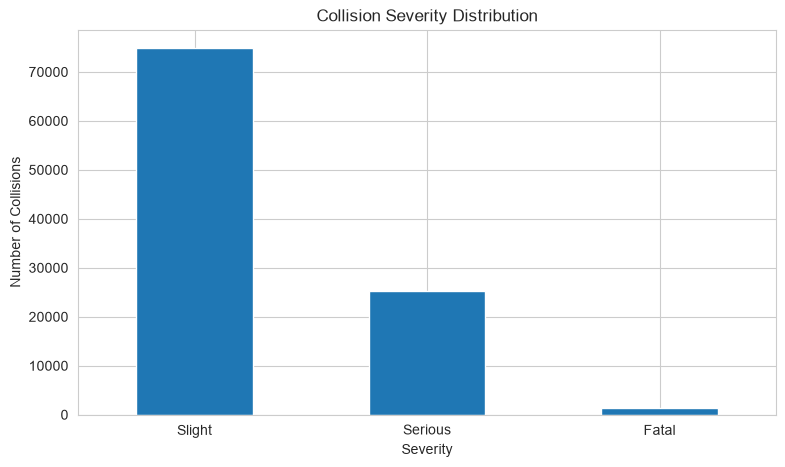

Percentage of collisions by severity:


severity_name
Slight     73.76
Serious    24.81
Fatal       1.43
Name: count, dtype: float64

In [12]:
# ============================================================
# 10. EDA — COLLISION SEVERITY DISTRIBUTION
# ============================================================

# Count collisions by severity.
severity_counts = (
    df["severity_name"]
    .value_counts()
    .reindex(["Slight", "Serious", "Fatal"])
)

# Plot the distribution
severity_counts.plot(
    kind="bar",
    title="Collision Severity Distribution"
)

plt.ylabel("Number of Collisions")
plt.xlabel("Severity")
plt.xticks(rotation=0)
plt.show()

# Calculate percentages
severity_percent = (
    severity_counts / len(df) * 100
).round(2)

print("Percentage of collisions by severity:")
display(severity_percent)

.size() → count ROWS

Use it when your question is:

“How many records are in each group?”

df.groupby("collision_hour").size()

Example:

8 AM  → 500 rows
9 AM  → 700 rows
10 AM → 650 rows

It counts the rows regardless of whether individual columns have NaN.
--------------------------------------------------------------------
.count() → count NON-MISSING VALUES in a specific column

Use it when your question is:

“How many non-empty values does this column have in each group?”

df.groupby("collision_hour")["collision_index"].count()

Example:

hour	collision_index	latitude
8	A	30.1
8	B	NaN
8	C	30.2

Then:

.size()                    → 3
["collision_index"].count() → 3
["latitude"].count()        → 2

Because latitude has one missing value.

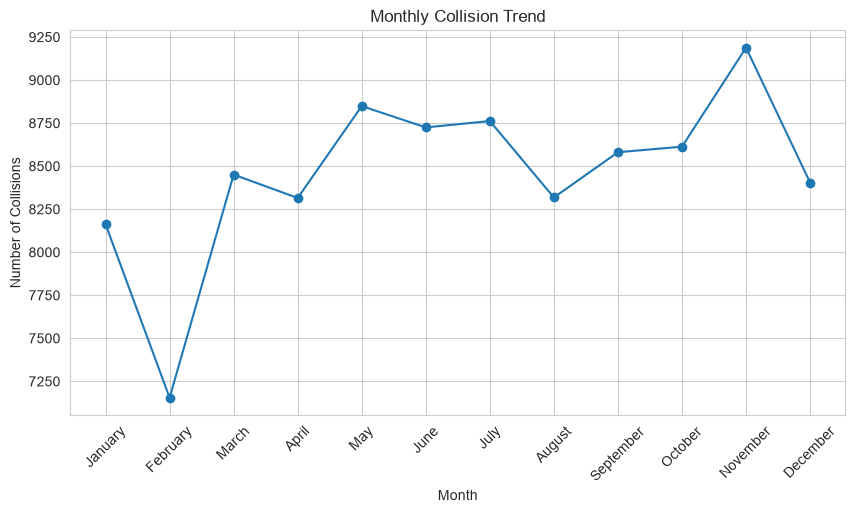

,collision_month,month_name,collision_count
0,1,January,8163
1,2,February,7155
2,3,March,8451
3,4,April,8315
4,5,May,8849
5,6,June,8725
6,7,July,8762
7,8,August,8318
8,9,September,8581
9,10,October,8613


In [15]:
# ============================================================
# 11. EDA — MONTHLY COLLISION TREND
# ============================================================

#Group all collisions by month, count the collisions in each month, then sort them from January to December.
monthly_trend = (
    #We put all collisions into groups based on their month.
    # For example:
    # January → all January collisions
    # February → all February collisions
    # March → all March collisions
    # ...
    df.groupby(
        ["collision_month", "month_name"],
        observed=True
        #We're choosing the collision ID column because each row represents one collision.
    )["collision_index"]
    #Count how many collision IDs are in each month
    .count()
    #This turns the grouped result back into a normal DataFrame and names the count column:collision_count
    .reset_index(name="collision_count")
    .sort_values("collision_month")
)

# Plot monthly trend
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_trend["month_name"],
    monthly_trend["collision_count"],
    marker="o"
)

plt.title("Monthly Collision Trend")
plt.xlabel("Month")
plt.ylabel("Number of Collisions")
plt.xticks(rotation=45)

plt.show()

display(monthly_trend)

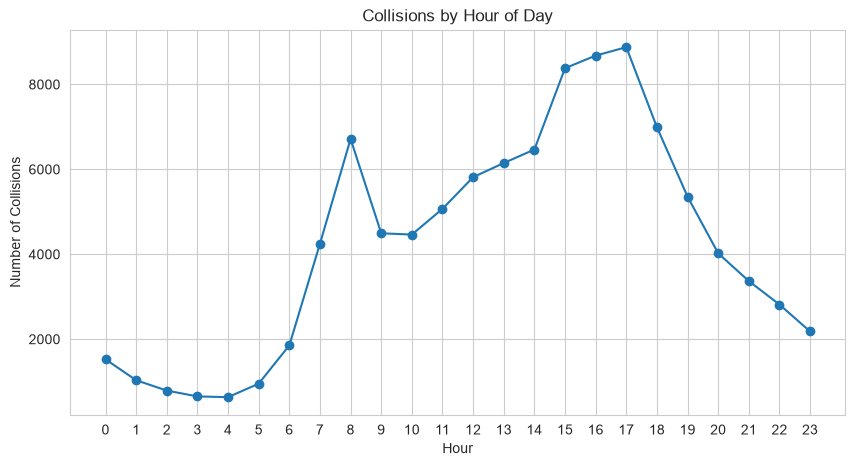

In [ ]:
# ============================================================
# 12. EDA — COLLISIONS BY HOUR
# ============================================================

# Count collisions for each hour of the day.
hourly_collisions = (
    #What does .size() do?First: df.groupby("collision_hour")groups your rows according to the hour.
    #Then: .size() counts the number of rows in each group.
    #.size() → count rows
    # .count() → count non-empty values in a column
    df.groupby("collision_hour", dropna=True)
    .size()
    .reset_index(name="collision_count")
)

# Plot the hourly pattern
plt.figure(figsize=(10, 5))

plt.plot(
    hourly_collisions["collision_hour"],
    hourly_collisions["collision_count"],
    marker="o"
)

plt.title("Collisions by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Number of Collisions")

plt.xticks(range(0, 24))

plt.show()

,time_of_day,total_collisions,severe_collisions,severe_rate_pct
0,Night,5583,1793,32.12
1,Morning,26843,6468,24.10
2,Afternoon,44365,11404,25.70
3,Evening,24734,6979,28.22


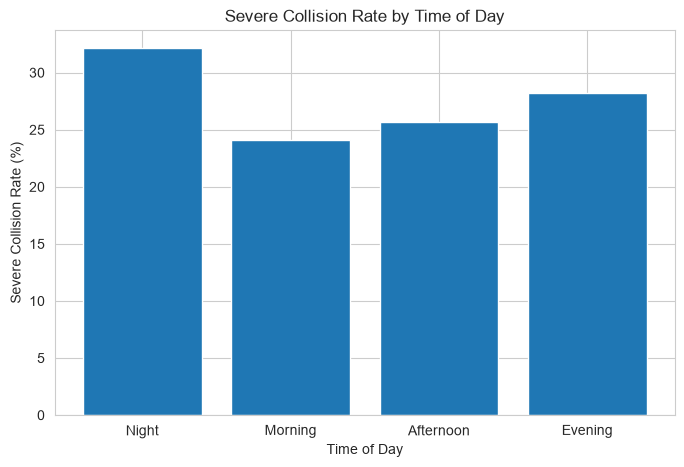

In [ ]:
# ============================================================
# 13. EDA — SEVERITY BY TIME OF DAY
# ============================================================

# Calculate the percentage of severe collisions
# within each time-of-day group.

time_severity = (
    df.groupby("time_of_day", observed=True)
    .agg(
        total_collisions=("collision_index", "count"),
        severe_collisions=("is_severe", "sum")
    )
    .reset_index()
)

# Calculate severe collision rate creates a new column
#What percentage of collisions in each time period were severe?
#Severe Rate = Severe Collisions ÷ Total Collisions × 100
time_severity["severe_rate_pct"] = (
    time_severity["severe_collisions"]
    / time_severity["total_collisions"]
    * 100
).round(2)

display(time_severity)

# Plot severe collision rate
plt.figure(figsize=(8, 5))

plt.bar(
    time_severity["time_of_day"].astype(str),
    time_severity["severe_rate_pct"]
)

plt.title("Severe Collision Rate by Time of Day")
plt.xlabel("Time of Day")
plt.ylabel("Severe Collision Rate (%)")

plt.show()

,weather_condition,total_collisions,severe_collisions,severe_rate_pct
0,Fine + high winds,715,230,32.17
2,Fog or mist,342,110,32.16
7,Snowing no high winds,235,67,28.51
4,Raining + high winds,880,247,28.07
1,Fine no high winds,83405,22336,26.78
5,Raining no high winds,10230,2666,26.06
3,Other,3314,689,20.79
8,Unknown,2385,297,12.45
6,Snowing + high winds,19,2,10.53


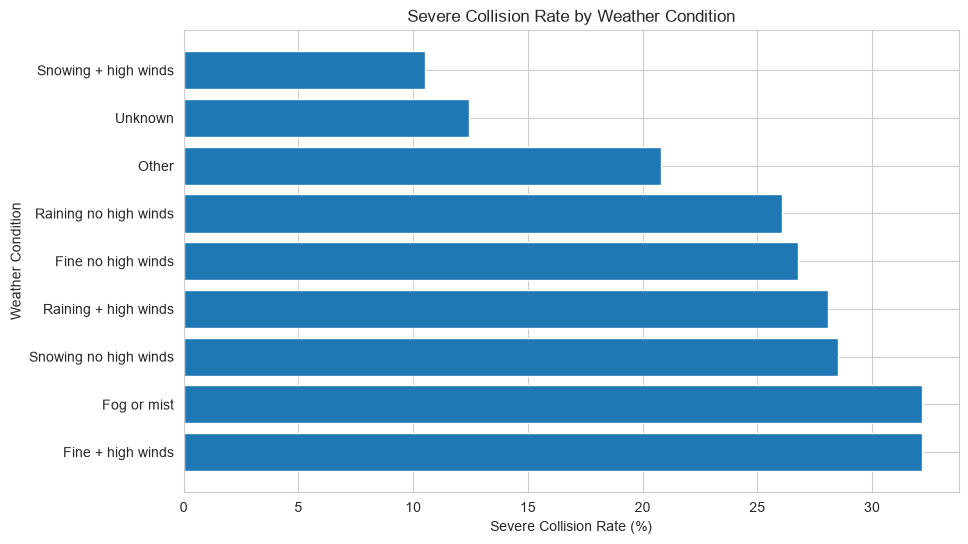

In [ ]:
# ============================================================
# 14. EDA — SEVERE COLLISION RATE BY WEATHER
# ============================================================

#After the groupby, weather_severity becomes a new, smaller table
#df["weather_condition"] → weather condition for every individual collision
#while:weather_severity["weather_condition"] → weather condition for each summarized group.
weather_severity = (
    df.groupby("weather_condition", observed=True)
    .agg(
        total_collisions=("collision_index", "count"),
        severe_collisions=("is_severe", "sum")
    )
    .reset_index()
)

weather_severity["severe_rate_pct"] = (
    weather_severity["severe_collisions"]
    / weather_severity["total_collisions"]
    * 100
).round(2)

# Sort from highest severe rate to lowest
weather_severity = weather_severity.sort_values(
    "severe_rate_pct",
    ascending=False
)

display(weather_severity)

plt.figure(figsize=(10, 6))

plt.barh(
    #Give me the weather_condition column from the weather_severity DataFrame.
    weather_severity["weather_condition"],
    weather_severity["severe_rate_pct"]
)

plt.title("Severe Collision Rate by Weather Condition")
plt.xlabel("Severe Collision Rate (%)")
plt.ylabel("Weather Condition")

plt.show()

,road_surface,total_collisions,severe_collisions,severe_rate_pct
2,Flood over 3cm deep,151,49,32.45
4,Snow,146,43,29.45
6,Wet or damp,22312,6123,27.44
1,Dry,75679,19929,26.33
3,Frost or ice,1261,312,24.74
0,Data missing,634,67,10.57
5,Unknown,1342,121,9.02


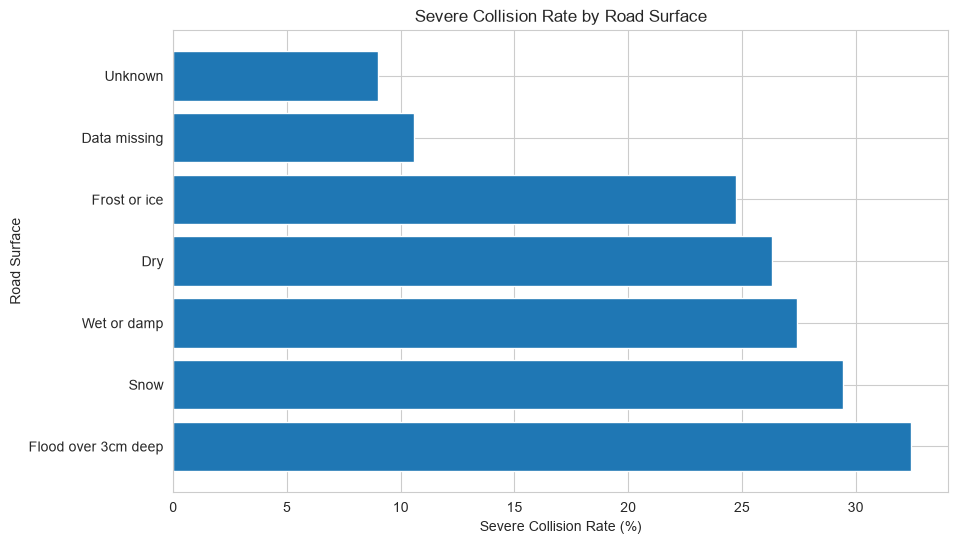

In [19]:
# ============================================================
# 15. EDA — SEVERE COLLISION RATE BY ROAD SURFACE
# ============================================================

surface_severity = (
    df.groupby("road_surface", observed=True)
    .agg(
        total_collisions=("collision_index", "count"),
        severe_collisions=("is_severe", "sum")
    )
    .reset_index()
)

surface_severity["severe_rate_pct"] = (
    surface_severity["severe_collisions"]
    / surface_severity["total_collisions"]
    * 100
).round(2)

surface_severity = surface_severity.sort_values(
    "severe_rate_pct",
    ascending=False
)

display(surface_severity)

plt.figure(figsize=(10, 6))

plt.barh(
    surface_severity["road_surface"],
    surface_severity["severe_rate_pct"]
)

plt.title("Severe Collision Rate by Road Surface")
plt.xlabel("Severe Collision Rate (%)")
plt.ylabel("Road Surface")

plt.show()

,area_type,total_collisions,severe_collisions,severe_rate_pct
0,Rural,34373,10614,30.88
1,Unallocated,4,2,50.00
2,Urban,67148,16028,23.87


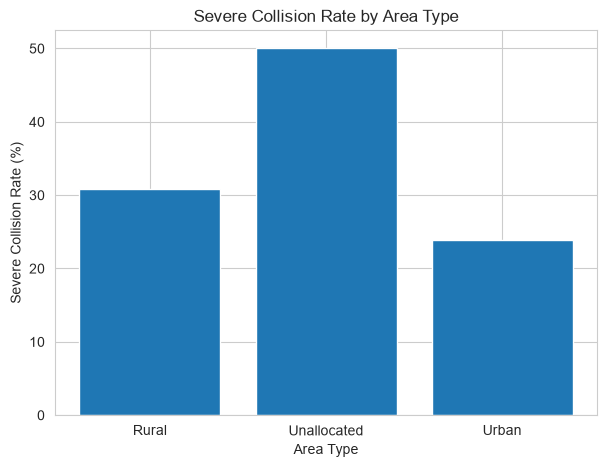

In [20]:
# ============================================================
# 16. EDA — SEVERE COLLISION RATE BY AREA
# ============================================================

area_severity = (
    df.groupby("area_type", observed=True)
    .agg(
        total_collisions=("collision_index", "count"),
        severe_collisions=("is_severe", "sum")
    )
    .reset_index()
)

area_severity["severe_rate_pct"] = (
    area_severity["severe_collisions"]
    / area_severity["total_collisions"]
    * 100
).round(2)

display(area_severity)

plt.figure(figsize=(7, 5))

plt.bar(
    area_severity["area_type"],
    area_severity["severe_rate_pct"]
)

plt.title("Severe Collision Rate by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Severe Collision Rate (%)")

plt.show()

,speed_limit,total_collisions,severe_collisions,severe_rate_pct
0,20,20045,4481,22.35
1,30,49673,12323,24.81
2,40,8886,2423,27.27
3,50,4612,1364,29.58
4,60,12709,4623,36.38
5,70,5600,1430,25.54


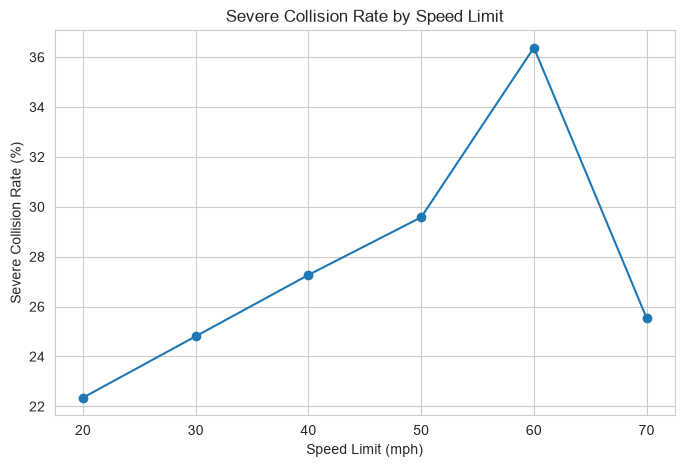

In [21]:
# ============================================================
# 17. EDA — SEVERE COLLISION RATE BY SPEED LIMIT
# ============================================================

speed_severity = (
    df.groupby("speed_limit")
    .agg(
        total_collisions=("collision_index", "count"),
        severe_collisions=("is_severe", "sum")
    )
    .reset_index()
)

speed_severity["severe_rate_pct"] = (
    speed_severity["severe_collisions"]
    / speed_severity["total_collisions"]
    * 100
).round(2)

speed_severity = speed_severity.sort_values("speed_limit")

display(speed_severity)

plt.figure(figsize=(8, 5))

plt.plot(
    speed_severity["speed_limit"],
    speed_severity["severe_rate_pct"],
    marker="o"
)

plt.title("Severe Collision Rate by Speed Limit")
plt.xlabel("Speed Limit (mph)")
plt.ylabel("Severe Collision Rate (%)")

plt.show()

,light_condition,total_collisions,severe_collisions,severe_rate_pct
3,Darkness - no lighting,5682,2062,36.29
2,Darkness - lights unlit,720,208,28.89
1,Darkness - lights lit,20705,5554,26.82
5,Daylight,72814,18444,25.33
4,Data missing,16,4,25.00
0,Darkness - lighting unknown,1588,372,23.43


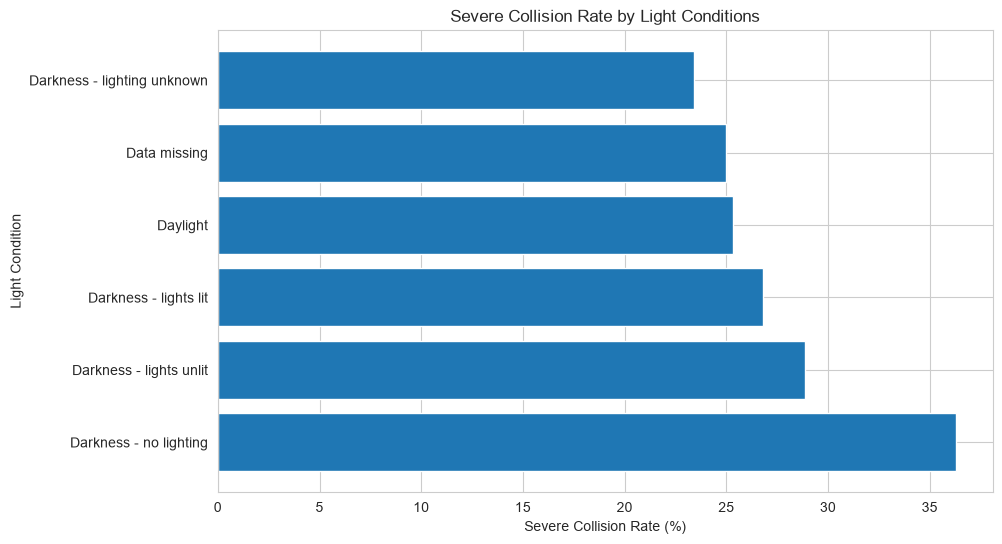

In [22]:
# ============================================================
# 18. EDA — SEVERE COLLISION RATE BY LIGHT CONDITIONS
# ============================================================

light_severity = (
    df.groupby("light_condition", observed=True)
    .agg(
        total_collisions=("collision_index", "count"),
        severe_collisions=("is_severe", "sum")
    )
    .reset_index()
)

light_severity["severe_rate_pct"] = (
    light_severity["severe_collisions"]
    / light_severity["total_collisions"]
    * 100
).round(2)

light_severity = light_severity.sort_values(
    "severe_rate_pct",
    ascending=False
)

display(light_severity)

plt.figure(figsize=(10, 6))

plt.barh(
    light_severity["light_condition"],
    light_severity["severe_rate_pct"]
)

plt.title("Severe Collision Rate by Light Conditions")
plt.xlabel("Severe Collision Rate (%)")
plt.ylabel("Light Condition")

plt.show()

,number_of_vehicles,total_collisions,severe_collisions,severe_rate_pct
0,1,30841,10122,32.82
1,2,61869,14071,22.74
2,3,6876,1876,27.28
3,4,1331,383,28.78
4,5,405,123,30.37
5,6,109,38,34.86
6,7,58,19,32.76
7,8,18,6,33.33
8,9,7,1,14.29
9,10,5,3,60.00


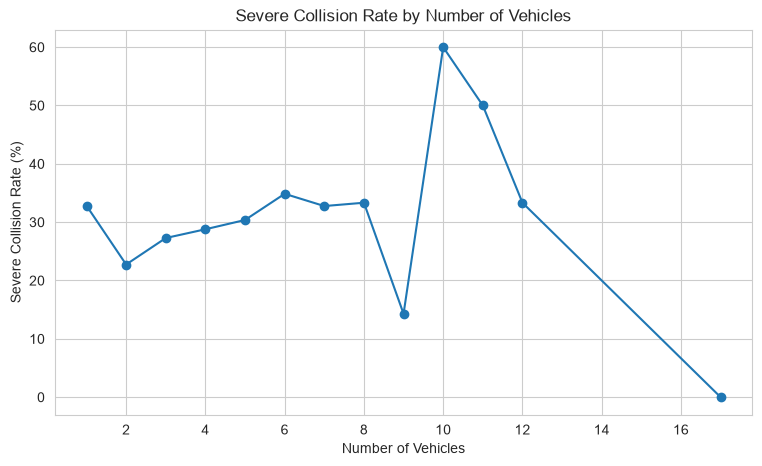

In [23]:
# ============================================================
# 19. EDA — SEVERE COLLISION RATE BY NUMBER OF VEHICLES
# ============================================================

vehicle_severity = (
    df.groupby("number_of_vehicles")
    .agg(
        total_collisions=("collision_index", "count"),
        severe_collisions=("is_severe", "sum")
    )
    .reset_index()
)

vehicle_severity["severe_rate_pct"] = (
    vehicle_severity["severe_collisions"]
    / vehicle_severity["total_collisions"]
    * 100
).round(2)

display(vehicle_severity)

plt.figure(figsize=(9, 5))

plt.plot(
    vehicle_severity["number_of_vehicles"],
    vehicle_severity["severe_rate_pct"],
    marker="o"
)

plt.title("Severe Collision Rate by Number of Vehicles")
plt.xlabel("Number of Vehicles")
plt.ylabel("Severe Collision Rate (%)")

plt.show()

,number_of_casualties,total_collisions,severe_collisions,severe_rate_pct
0,1,83317,20778,24.94
1,2,13126,3838,29.24
2,3,3301,1231,37.29
3,4,1178,476,40.41
4,5,389,194,49.87
5,6,113,60,53.10
6,7,46,25,54.35
7,8,17,11,64.71
8,9,9,6,66.67
9,10,9,8,88.89


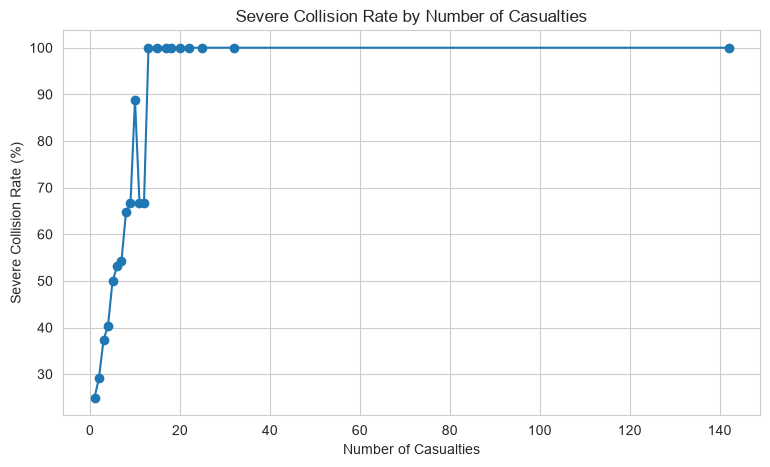

In [25]:
# ============================================================
# 20. EDA — SEVERE COLLISION RATE BY NUMBER OF CASUALTIES
# ============================================================

casualty_severity = (
    df.groupby("number_of_casualties")
    .agg(
        total_collisions=("collision_index", "count"),
        severe_collisions=("is_severe", "sum")
    )
    .reset_index()
)

casualty_severity["severe_rate_pct"] = (
    casualty_severity["severe_collisions"]
    / casualty_severity["total_collisions"]
    * 100
).round(2)

display(casualty_severity)

plt.figure(figsize=(9, 5))

plt.plot(
    casualty_severity["number_of_casualties"],
    casualty_severity["severe_rate_pct"],
    marker="o"
)

plt.title("Severe Collision Rate by Number of Casualties")
plt.xlabel("Number of Casualties")
plt.ylabel("Severe Collision Rate (%)")

plt.show()

,driver_age_group,severity_name,collision_count,percentage
0,25 or younger,Fatal,198,1.44
1,25 or younger,Serious,3686,26.86
2,25 or younger,Slight,9841,71.70
3,26-35,Fatal,249,1.11
4,26-35,Serious,5171,22.96
5,26-35,Slight,17105,75.94
6,36-50,Fatal,449,1.31
7,36-50,Serious,8106,23.64
8,36-50,Slight,25731,75.05
9,51-65,Fatal,358,1.95


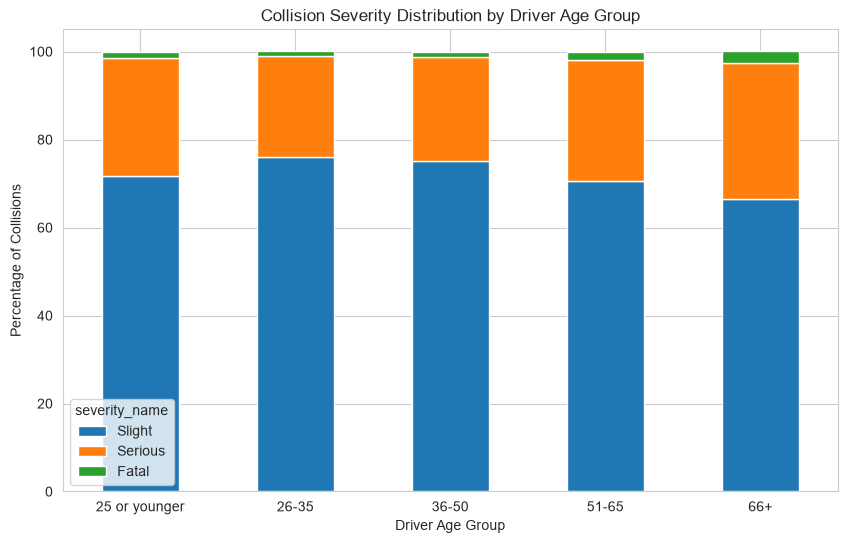

In [ ]:
# ============================================================
# 21. EDA — DRIVER AGE GROUP VS SEVERITY
# ============================================================

age_severity = (
    df.groupby(
        ["driver_age_group", "severity_name"],
        observed=True
    )
    #counts the number of rows in each group.
    .size()
    #The .size() result is a Series,reset_index() turns it back into a normal DataFrame name="collision_count" gives the count column a name.
    .reset_index(name="collision_count")
)

# Convert counts into percentages within each age group
age_totals = (
    age_severity
    .groupby("driver_age_group", observed=True)["collision_count"]
    .transform("sum")
)

age_severity["percentage"] = (
    age_severity["collision_count"]
    / age_totals
    * 100
).round(2)

display(age_severity)

# Create a table with severity as columns
#What does .pivot() do? It rearranges that table.
#index="driver_age_group" → Put the age groups as rows.
#columns="severity_name" → Turn the severity values (Fatal, Serious, Slight) into columns.
#values="percentage" → Put the percentage values inside the table.

age_pivot = age_severity.pivot(
    index="driver_age_group",
    columns="severity_name",
    values="percentage"
).fillna(0)

# Keep severity order consistent
age_pivot = age_pivot.reindex(
    columns=["Slight", "Serious", "Fatal"]
)

age_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Collision Severity Distribution by Driver Age Group")
plt.xlabel("Driver Age Group")
plt.ylabel("Percentage of Collisions")
plt.xticks(rotation=0)

plt.show()

,day_type,total_collisions,severe_collisions,severe_rate_pct
0,Weekday,76673,19571,25.53
1,Weekend,24852,7073,28.46


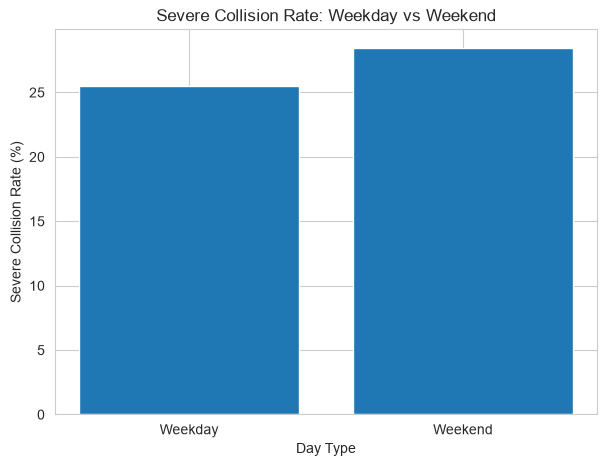

In [27]:
# ============================================================
# 22. EDA — WEEKDAY VS WEEKEND
# ============================================================

df["day_type"] = np.where(
    df["is_weekend"] == 1,
    "Weekend",
    "Weekday"
)

day_severity = (
    df.groupby("day_type")
    .agg(
        total_collisions=("collision_index", "count"),
        severe_collisions=("is_severe", "sum")
    )
    .reset_index()
)

day_severity["severe_rate_pct"] = (
    day_severity["severe_collisions"]
    / day_severity["total_collisions"]
    * 100
).round(2)

display(day_severity)

plt.figure(figsize=(7, 5))

plt.bar(
    day_severity["day_type"],
    day_severity["severe_rate_pct"]
)

plt.title("Severe Collision Rate: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Severe Collision Rate (%)")

plt.show()

The problem is that fatal_casualties, serious_casualties, and slight_casualties are part of the outcome itself, so including them in a correlation analysis can give you a misleadingly strong relationship.

Think about what we're trying to discover

Our project asks:
What conditions are associated with collision severity?

So we want to investigate relationships like:

speed limit          ↔ collision severity
number of vehicles   ↔ collision severity
driver age           ↔ collision severity
number of casualties ↔ collision severity

These are interesting because they might tell us something about the conditions surrounding the collision.

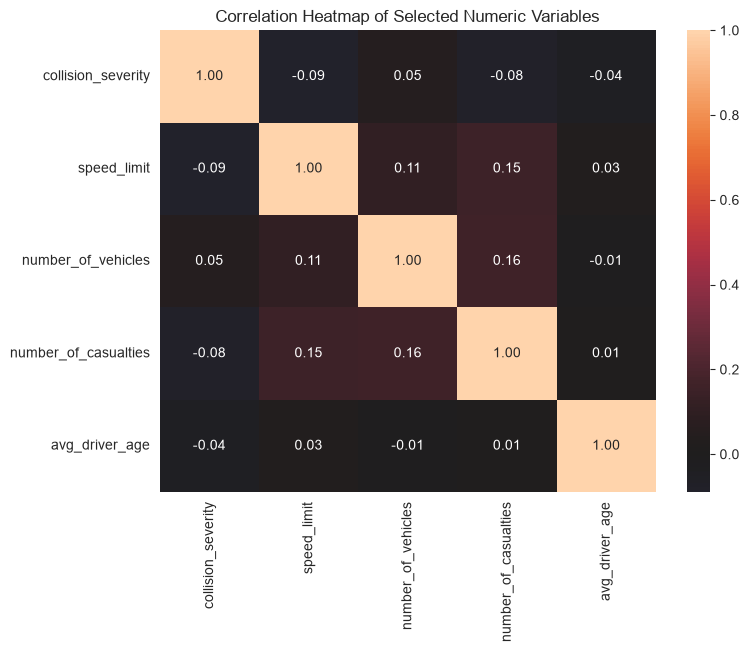

In [28]:
# ============================================================
# 23. EDA — CORRELATION HEATMAP
# ============================================================

# Use only meaningful numerical variables.
#
# We intentionally do NOT include:
# fatal_casualties
# serious_casualties
# slight_casualties
#
# because these are components of the casualty outcome and
# would create misleading/tautological correlations.

numeric_cols = [
    "collision_severity",
    "speed_limit",
    "number_of_vehicles",
    "number_of_casualties",
    "avg_driver_age"
]

correlation_matrix = (
    df[numeric_cols]
    .corr()
    .round(2)
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    center=0,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Selected Numeric Variables")

plt.show()

Variable	Correlation with collision severity
Speed limit	-0.09
Number of vehicles	0.05
Number of casualties	-0.08
Average driver age	-0.04

These are all very close to 0.

So the heatmap is telling us:

There is no strong linear relationship between collision severity and these numerical variables in this dataset.

One VERY important thing

This heatmap doesn't mean your project found nothing.

Correlation only measures linear relationships between numerical variables.

Your other analyses — weather, road surface, light conditions, area type, time of day, speed limit categories, etc. — use group comparisons and severe-collision rates, which can reveal patterns that this heatmap doesn't capture.

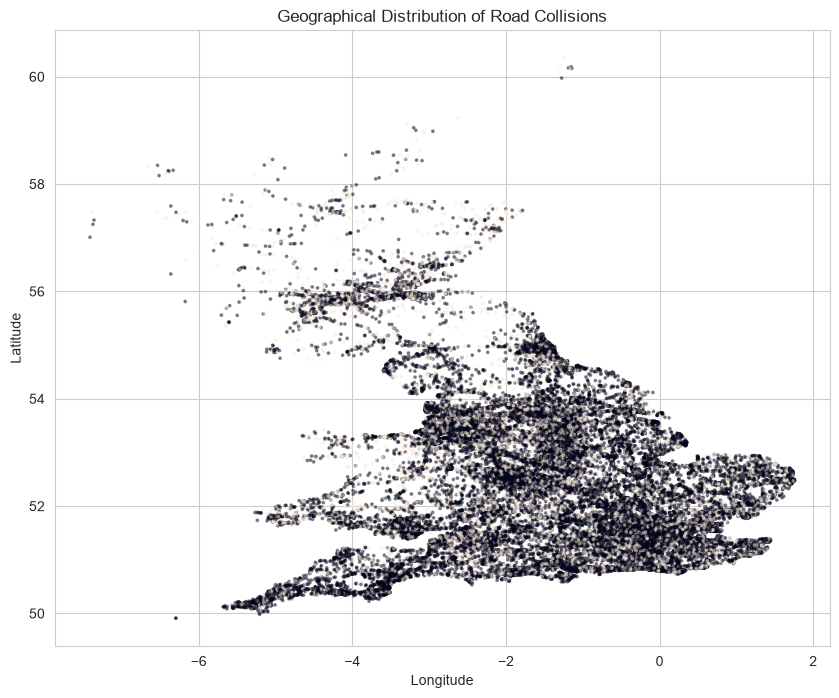

Collisions with available coordinates: 101523


In [29]:
# ============================================================
# 24. EDA — COLLISION LOCATION
# ============================================================

# Keep only collisions that have valid coordinates.
# We are NOT deleting these rows from the main dataset.
# We are only using available coordinates for this chart.

map_data = df.dropna(
    subset=["longitude", "latitude"]
)

plt.figure(figsize=(10, 8))

# Plot collisions using longitude and latitude.
# Color represents whether the collision was severe.
plt.scatter(
    map_data["longitude"],
    map_data["latitude"],
    c=map_data["is_severe"],
    s=3,
    alpha=0.4
)

plt.title("Geographical Distribution of Road Collisions")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.show()

print(
    "Collisions with available coordinates:",
    len(map_data)
)

In [30]:
# ============================================================
# 25. KEY PROJECT KPIs
# ============================================================

total_collisions = len(df)

fatal_collisions = (
    df["is_fatal"].sum()
)

serious_collisions = (
    df["is_serious"].sum()
)

severe_collisions = (
    df["is_severe"].sum()
)

total_casualties = (
    df["number_of_casualties"].sum()
)

total_vehicles = (
    df["number_of_vehicles"].sum()
)

severe_rate = (
    severe_collisions / total_collisions * 100
)

fatal_rate = (
    fatal_collisions / total_collisions * 100
)

print("========== SAFEROAD KPI SUMMARY ==========")

print("Total Collisions:", total_collisions)
print("Fatal Collisions:", fatal_collisions)
print("Serious Collisions:", serious_collisions)
print("Severe Collisions:", severe_collisions)
print("Total Casualties:", total_casualties)
print("Total Vehicles:", total_vehicles)

print(
    "Severe Collision Rate:",
    round(severe_rate, 2),
    "%"
)

print(
    "Fatal Collision Rate:",
    round(fatal_rate, 2),
    "%"
)

========== SAFEROAD KPI SUMMARY ==========
Total Collisions: 101525
Fatal Collisions: 1453
Serious Collisions: 25191
Severe Collisions: 26644
Total Casualties: 127883
Total Vehicles: 183948
Severe Collision Rate: 26.24 %
Fatal Collision Rate: 1.43 %


In [31]:
# ============================================================
# 26. EXPORT ANALYSIS RESULTS
# ============================================================

# Export the most important analysis tables.
# These can later be used for Excel, Power BI or Tableau.

monthly_trend.to_csv(
    "monthly_trend.csv",
    index=False
)

time_severity.to_csv(
    "severity_by_time_of_day.csv",
    index=False
)

weather_severity.to_csv(
    "severity_by_weather.csv",
    index=False
)

surface_severity.to_csv(
    "severity_by_road_surface.csv",
    index=False
)

area_severity.to_csv(
    "severity_by_area.csv",
    index=False
)

speed_severity.to_csv(
    "severity_by_speed_limit.csv",
    index=False
)

light_severity.to_csv(
    "severity_by_light.csv",
    index=False
)

age_severity.to_csv(
    "severity_by_driver_age.csv",
    index=False
)

day_severity.to_csv(
    "severity_by_day_type.csv",
    index=False
)

print("Analysis CSV files exported successfully.")

Analysis CSV files exported successfully.


In [32]:
# ============================================================
# 27. FINAL PROJECT CHECK
# ============================================================

print("========== FINAL CHECK ==========")

# Dataset size
print("Rows:", len(df))
print("Columns:", len(df.columns))

# One row should represent one collision
print(
    "Unique collision IDs:",
    df["collision_index"].nunique()
)

print(
    "Duplicate collision IDs:",
    df["collision_index"].duplicated().sum()
)

# Exact duplicate rows
print(
    "Exact duplicate rows:",
    df.duplicated().sum()
)

# Missing coordinates are allowed
print(
    "Missing coordinates:",
    df[["latitude", "longitude"]].isna().any(axis=1).sum()
)

# Missing driver age is allowed
print(
    "Missing average driver age:",
    df["avg_driver_age"].isna().sum()
)

# Check severity values
print(
    "Severity categories:",
    df["severity_name"].unique()
)

print("\nPython cleaning and analysis completed successfully.")

========== FINAL CHECK ==========
Rows: 101525
Columns: 45
Unique collision IDs: 101525
Duplicate collision IDs: 0
Exact duplicate rows: 0
Missing coordinates: 2
Missing average driver age: 6028
Severity categories: <StringArray>
['Slight', 'Serious', 'Fatal']
Length: 3, dtype: str

Python cleaning and analysis completed successfully.
